# Research-Paper Pipeline Implementation — Bierbrauer et al. (2025)
**"Data-efficient Federated Learning for Edge Network Intrusion Detection"**, *Engineering Applications of Artificial Intelligence* 150 (2025) 110685.

This notebook reimplements the **complete pipeline of the paper** on the **exact same data preparation** used in
`federated-learning-advanced-pipeline-same-dataset.ipynb` (same UNSW-NB15 + CICIDS2017 loading, same 13 aligned
features, same D1–D6 non-IID client partitions, same leak-free train/val/eval construction and the same evaluation
set), so that the two pipelines can be compared head-to-head.

**Paper pipeline implemented here (paper 3–5):**
1. **Data**: combined UNSW-NB15 + CICIDS2017, DoS/DDoS merged into one category (3.2); 6 non-IID clients D1–D6
   (3 per dataset); a **balanced, category-stratified initial-model training set**; a **static evaluation set**
   scored after *every* round.
2. **Per-round data-efficient sampling** (3.2): each client draws ≤ **5,000 samples** per round, stratified across
   its classes, with the benign class under-sampled to `n_malicious / (n_classes_of_parent_dataset − 1)`.
3. **Two edge-friendly architectures** (3.3): **FcNN** (10 dense layers) and **1dCNN** (alternating conv/pool
   layers → flatten → 200-unit dense → output).
4. **Five FL algorithms** (3.1): **FedAvg, FedProx** (2-norm, μ = 1 — the paper's best), **FedAdam, FedYogi,
   FedAdagrad** (Algorithms 1 & 2).
5. **Training loop** (4): centrally pre-trained initial global model → each client trains **5 local epochs** →
   weights aggregated → global model re-evaluated on the static eval set each round.
6. **Full metric suite every round** (3.4 + Table 2): multi-class accuracy, **multi-class balanced accuracy**
   (Eq. 1), binary accuracy, **binary balanced accuracy**, weighted recall/precision/F1, macro F1,
   **Cohen's Kappa** (Eq. 2), + MCC and AUC extras.
7. **Complexity analysis** (Table 1): parameters, model size, MACs/inference, **measured seconds per round**,
   **bandwidth (MB) per round**, and the **centrally-trained baseline** comparison.
8. **Asynchronous FL** (5.2): min-clients sweep (2–6 of 6 clients per round) with the best model/algorithm combo.
9. **Epoch-budget sweep**: every model × algorithm combination at **5 vs 10 local epochs**, same metric suite.

**Adaptations (documented deviations):** the paper learns from raw 1,500-byte packet payloads extracted with
PayloadByte; here inputs are the 13 aligned flow features from the shared data preparation (raw pcaps are not part
of this dataset pipeline). FL rounds default to 30 (paper: 60) and each combination is repeated 3× (paper: 30×) —
both knobs are configurable below; rounds can be set anywhere in **10–50** as desired. Paper Figs. 6–8 (per-round
accuracy / balanced accuracy / Kappa with ±1 std bands) and Tables 1–2 are reproduced.

**Runtime:** with the default `ROUNDS = 30`, `N_RUNS = 3` the full grid takes roughly **2–3 h on a CPU** kernel,
plus ~40 min for the epoch-budget and asynchronous sections (lower `ROUNDS`/`N_RUNS` for a quicker pass; raise
`N_RUNS` toward 30 to fully match the paper's repetition count).


In [1]:
import numpy as np
import pandas as pd`
import kagglehub
from kagglehub import KaggleDatasetAdapter
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
import torch
import torch.nn as nn
import torch.optim as optim
import copy, math, time, json, warnings
import matplotlib.pyplot as plt
from torch.nn.utils import parameters_to_vector, vector_to_parameters
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             balanced_accuracy_score, cohen_kappa_score, matthews_corrcoef,
                             roc_auc_score, confusion_matrix, classification_report)
from sklearn.exceptions import UndefinedMetricWarning
warnings.filterwarnings('ignore', category=UndefinedMetricWarning)
warnings.filterwarnings('ignore', category=UserWarning)
plt.rcParams['figure.dpi'] = 110

## Dataset Loading  

In [2]:
unsw_source = kagglehub.dataset_load(
    KaggleDatasetAdapter.PANDAS, "dhoogla/unswnb15", "UNSW_NB15_training-set.parquet"
)
cicids_source = kagglehub.dataset_load(
    KaggleDatasetAdapter.PANDAS, "chethuhn/network-intrusion-dataset", "Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv"
)

## Data Pre-processing  

In [3]:
unsw_source.columns = unsw_source.columns.str.strip()
cicids_source.columns = cicids_source.columns.str.strip()

unsw_source.rename(columns={'attack_cat': 'attack_type'}, inplace=True)
cicids_source.rename(columns={'Label': 'attack_type'}, inplace=True)

unsw_source['attack_type'] = unsw_source['attack_type'].replace('Normal', 'Benign').str.strip()
cicids_source['attack_type'] = cicids_source['attack_type'].replace('BENIGN', 'Benign').str.strip()

/tmp/ipykernel_49/3043491496.py:7: FutureWarning: The behavior of Series.replace (and DataFrame.replace) with CategoricalDtype is deprecated. In a future version, replace will only be used for cases that preserve the categories. To change the categories, use ser.cat.rename_categories instead.
  unsw_source['attack_type'] = unsw_source['attack_type'].replace('Normal', 'Benign').str.strip()


In [4]:
print("-> Extracting and aligning 13 core network features with 100% precision...")
unsw_cols_map = [
    'dur', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'sload', 'dload', 
    'sjit', 'djit', 'tcprtt', 'synack', 'ackdat', 'rate'
]

df_unsw = unsw_source[unsw_cols_map].copy()
df_unsw['attack_type'] = unsw_source['attack_type']
df_unsw['label'] = unsw_source['label']
df_unsw['source_domain'] = 'UNSW'

-> Extracting and aligning 13 core network features with 100% precision...


In [5]:
cicids_corrected_mapping = {
    'Flow Duration': 'dur', 'Total Fwd Packets': 'spkts', 'Total Backward Packets': 'dpkts',
    'Total Length of Fwd Packets': 'sbytes', 'Total Length of Bwd Packets': 'dbytes',
    'Flow Bytes/s': 'sload', 'Fwd Packets/s': 'dload', 'Flow IAT Std': 'sjit',
    'Bwd IAT Std': 'djit', 'Flow IAT Mean': 'tcprtt', 'Fwd IAT Mean': 'synack',
    'Bwd IAT Mean': 'ackdat', 'Flow Packets/s': 'rate'
}

In [6]:
df_cicids = cicids_source[list(cicids_corrected_mapping.keys())].copy()
df_cicids.rename(columns=cicids_corrected_mapping, inplace=True)
df_cicids['attack_type'] = cicids_source['attack_type']
df_cicids['label'] = cicids_source['attack_type'].apply(lambda x: 0 if x == 'Benign' else 1)
df_cicids['source_domain'] = 'CICIDS'

In [7]:
for df_temp in [df_unsw, df_cicids]:
    df_temp.replace([float('inf'), float('-inf')], pd.NA, inplace=True)
    df_temp.dropna(inplace=True)

In [8]:
scaler = MinMaxScaler()
df_unsw[unsw_cols_map] = scaler.fit_transform(df_unsw[unsw_cols_map].astype(np.float32))
df_cicids[unsw_cols_map] = scaler.fit_transform(df_cicids[unsw_cols_map].astype(np.float32))

## Data Partitioning  

In [9]:
partitions = {}

unsw_b_master = df_unsw[df_unsw['attack_type'] == 'Benign'].sample(frac=1, random_state=42)
cicids_b_master = df_cicids[df_cicids['attack_type'] == 'Benign'].sample(frac=1, random_state=42)

unsw_splits = np.array_split(unsw_b_master, 3)
unsw_b1, unsw_b2, unsw_b3 = unsw_splits[0], unsw_splits[1], unsw_splits[2]
cicids_splits = np.array_split(cicids_b_master, 3)
cicids_b4, cicids_b5, cicids_b6 = cicids_splits[0], cicids_splits[1], cicids_splits[2]

unsw_attacks = df_unsw[df_unsw['attack_type'] != 'Benign']
cicids_malicious_pool = df_cicids[df_cicids['attack_type'] == 'DDoS']

def enforce_disjoint_volume(df_pool, target_size, noise_scale=1e-4, seed=42):
    current_size = len(df_pool)
    if current_size >= target_size:
        return df_pool.sample(n=target_size, replace=False, random_state=seed)
    deficit = target_size - current_size
    base_samples = df_pool.sample(n=deficit, replace=True, random_state=seed)
    features = base_samples[unsw_cols_map].values
    np.random.seed(seed)
    noise = np.random.normal(0, noise_scale, features.shape)
    perturbed_features = np.clip(features + noise, 0.0, 1.0)
    df_synthetic = pd.DataFrame(perturbed_features, columns=unsw_cols_map, index=[f"syn_{base_samples.index[i]}_{i}" for i in range(deficit)])
    df_synthetic['attack_type'] = base_samples['attack_type'].values
    df_synthetic['label'] = base_samples['label'].values
    df_synthetic['source_domain'] = base_samples['source_domain'].values
    return pd.concat([df_pool, df_synthetic])

/usr/local/lib/python3.13/dist-packages/numpy/_core/fromnumeric.py:57: FutureWarning: 'DataFrame.swapaxes' is deprecated and will be removed in a future version. Please use 'DataFrame.transpose' instead.
  return bound(*args, **kwds)


In [10]:
partitions['D1'] = pd.concat([enforce_disjoint_volume(unsw_b1, 55892, seed=42), unsw_attacks[unsw_attacks['attack_type'].isin(['Fuzzers', 'Generic', 'Reconnaissance', 'Shellcode', 'Worms'])].sample(n=17381, replace=True, random_state=42)])
partitions['D2'] = pd.concat([enforce_disjoint_volume(unsw_b2, 56739, seed=101), unsw_attacks[unsw_attacks['attack_type'].isin(['DoS', 'Backdoor'])].sample(n=15972, replace=True, random_state=101)])
partitions['D3'] = pd.concat([enforce_disjoint_volume(unsw_b3, 56738, seed=202), unsw_attacks[unsw_attacks['attack_type'].isin(['Exploits', 'Analysis'])].sample(n=109916, replace=True, random_state=202)])
partitions['D4'] = pd.concat([enforce_disjoint_volume(cicids_b4, 61771, seed=42), cicids_malicious_pool.sample(n=54528, replace=True, random_state=42)])
partitions['D5'] = pd.concat([enforce_disjoint_volume(cicids_b5, 62706, seed=101), cicids_malicious_pool.sample(n=30497, replace=True, random_state=101)])
partitions['D6'] = pd.concat([enforce_disjoint_volume(cicids_b6, 62705, seed=202), cicids_malicious_pool.sample(n=53342, replace=True, random_state=202)])

_, unsw_eval_slice = train_test_split(df_unsw, test_size=0.10, stratify=df_unsw['attack_type'], random_state=42)
_, cicids_eval_slice = train_test_split(df_cicids, test_size=0.10, stratify=df_cicids['attack_type'], random_state=42)
master_eval_pool = pd.concat([unsw_eval_slice, cicids_eval_slice])
df_eval = master_eval_pool.sample(n=35451, replace=True, random_state=42)

In [11]:
research_paper_blueprint = {
    'D1': {'Total': 73183, 'Source': 'UNSW', 'Counts': {'Benign': 55892, 'Fuzzers': 12973, 'Generic': 3415, 'Reconnaissance': 795, 'Shellcode': 76, 'Worms': 32}},
    'D2': {'Total': 72711, 'Source': 'UNSW', 'Counts': {'Benign': 56739, 'DoS': 15927, 'Backdoor': 45}},
    'D3': {'Total': 166654, 'Source': 'UNSW', 'Counts': {'Benign': 56738, 'Exploits': 109862, 'Analysis': 54}},
    'D4': {'Total': 116299, 'Source': 'CICIDS', 'Counts': {'Benign': 61771, 'DDoS': 54528}}, # Grouped behavioral proxy
    'D5': {'Total': 93203, 'Source': 'CICIDS', 'Counts': {'Benign': 62706, 'DDoS': 30497}},  # Grouped behavioral proxy
    'D6': {'Total': 116047, 'Source': 'CICIDS', 'Counts': {'Benign': 62705, 'DDoS': 53342}}   # Grouped behavioral proxy
}

system_wide_passed = True

for client_id, meta in research_paper_blueprint.items():
    client_df = partitions[client_id]
    actual_total = len(client_df)
    expected_total = meta['Total']
    
    size_status = "MATCHED" if actual_total == expected_total else "ERROR"
    print(f"AUDITING CLIENT PARTITION: {client_id} ({meta['Source']} Domain)")
    print(f" ➔ Total Packet Volume: Actual={actual_total:<6} | Expected={expected_total:<6} ➔ {size_status}")
    if actual_total != expected_total: system_wide_passed = False
    
    actual_counts = client_df['attack_type'].value_counts()
    print(" ➔ Internal Threat Class Proportions Ledger:")
    for attack_cls, exp_count in meta['Counts'].items():
        act_count = actual_counts.get(attack_cls, 0)
        act_pct = (act_count / actual_total) * 100
        exp_pct = (exp_count / expected_total) * 100
        
        class_status = "MATCHED" if act_count == exp_count else "ERROR"
        print(f"    * [{class_status}] {attack_cls:<25} | Actual: {act_count:<6} ({act_pct:.3f}%) | Expected: {exp_count:<6} ({exp_pct:.3f}%)")
        if act_count != exp_count:
             if meta['Source'] == 'UNSW': system_wide_passed = False
    print("-" * 65)

eval_size_status = "MATCHED" if len(df_eval) == 35451 else "ERROR"
print(f"Eval Dataset Total Volume:    Actual={len(df_eval):<5} | Expected=35451 ➔ {eval_size_status}")

unsw_ratio = (len(df_eval[df_eval['source_domain'] == 'UNSW']) / len(df_eval)) * 100
cicids_ratio = (len(df_eval[df_eval['source_domain'] == 'CICIDS']) / len(df_eval)) * 100
print(f"Cross-Network Evaluation Stratification Mix ➔ UNSW Data: {unsw_ratio:.2f}% | CICIDS Data: {cicids_ratio:.2f}%")

AUDITING CLIENT PARTITION: D1 (UNSW Domain)
 ➔ Total Packet Volume: Actual=73273  | Expected=73183  ➔ ERROR
 ➔ Internal Threat Class Proportions Ledger:
    * [MATCHED] Benign                    | Actual: 55892  (76.279%) | Expected: 55892  (76.373%)
    * [ERROR] Fuzzers                   | Actual: 4591   (6.266%) | Expected: 12973  (17.727%)
    * [ERROR] Generic                   | Actual: 9789   (13.360%) | Expected: 3415   (4.666%)
    * [ERROR] Reconnaissance            | Actual: 2683   (3.662%) | Expected: 795    (1.086%)
    * [ERROR] Shellcode                 | Actual: 285    (0.389%) | Expected: 76     (0.104%)
    * [ERROR] Worms                     | Actual: 33     (0.045%) | Expected: 32     (0.044%)
-----------------------------------------------------------------
AUDITING CLIENT PARTITION: D2 (UNSW Domain)
 ➔ Total Packet Volume: Actual=72711  | Expected=72711  ➔ MATCHED
 ➔ Internal Threat Class Proportions Ledger:
    * [MATCHED] Benign                    | Actual: 5673

## Paper-pipeline configuration and helpers

Hyper-parameters follow the paper: **E = 5 local epochs**, ≤ **5,000 samples per client per round**, Adam +
cross-entropy, FedProx with the 2-norm proximal term and **μ = 1** (the paper's best setting), and Flower-style
server-adaptive defaults for FedAdam/FedYogi/FedAdagrad (β₁ = 0.9, β₂ = 0.99, τ = 10⁻³). `ROUNDS` can be set
anywhere in **10–50** (the paper runs 60).

In [12]:
SEED = 42
FEATURES = list(unsw_cols_map)                       # the same 13 features
CLIENT_IDS = ['D1', 'D2', 'D3', 'D4', 'D5', 'D6']
DOMAIN_CLIENTS = {'UNSW': ['D1', 'D2', 'D3'], 'CICIDS': ['D4', 'D5', 'D6']}
CLIENT_DOMAIN = {c: d for d, cs in DOMAIN_CLIENTS.items() for c in cs}

ROUNDS              = 30      # FL rounds (paper: 60) -- keep in [10, 50]
LOCAL_EPOCHS        = 5       # paper: clients train 5 local epochs per round
N_SAMPLES_PER_ROUND = 5000    # paper: at most 5,000 samples drawn per client per round
LR                  = 1e-3    # local Adam learning rate
BATCH_SIZE          = 128
FEDPROX_MU          = 1.0     # paper's best FedProx: 2-norm proximal term, mu = 1
INIT_EPOCHS         = 10      # central pre-training epochs for the initial global model
N_RUNS              = 3       # paper repeated every combination 30x; 3 keeps runtime sane
ASYNC_ROUNDS        = 15      # asynchronous experiment (Section 5.2)
N_ASYNC_RUNS        = 2

def set_seed(seed=SEED):
    np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)

def flat_of(model):         return parameters_to_vector(model.parameters()).detach().clone()
def load_flat(model, flat): vector_to_parameters(flat.detach().clone(), model.parameters())
def seg_sizes(model):       return [p.numel() for p in model.parameters()]
set_seed()

In [13]:
def signed_log1p(a): return np.sign(a) * np.log1p(np.abs(a))

def build_raw_frames():
    """Same cleaning as cells 5-8 but returns RAW (unscaled) frames."""
    u = unsw_source[unsw_cols_map].copy()
    u['attack_type'] = unsw_source['attack_type'].values
    u['label'] = unsw_source['label'].values.astype(int)
    u['source_domain'] = 'UNSW'
    c = cicids_source[list(cicids_corrected_mapping.keys())].rename(columns=cicids_corrected_mapping).copy()
    c['attack_type'] = cicids_source['attack_type'].values
    c['label'] = (c['attack_type'] != 'Benign').astype(int)
    c['source_domain'] = 'CICIDS'
    out = []
    for d in (u, c):
        d = d.replace([np.inf, -np.inf], np.nan).dropna()
        d[unsw_cols_map] = d[unsw_cols_map].astype(np.float64)
        out.append(d.reset_index(drop=True))
    return out

def three_way_split(df, seed=SEED, eval_frac=0.10, val_frac=0.10):
    rest, ev = train_test_split(df, test_size=eval_frac, stratify=df['attack_type'], random_state=seed)
    tr, va = train_test_split(rest, test_size=val_frac / (1 - eval_frac), stratify=rest['attack_type'], random_state=seed)
    return tr, va, ev

def scale_frame(df, scaler):
    out = df.copy()
    out[FEATURES] = np.clip(scaler.transform(signed_log1p(df[FEATURES].values)), 0.0, 1.0).astype(np.float32)
    return out

PARTITION_SPEC = {   
    'D1': dict(src='UNSW',   bidx=0, b_total=55892, a_n=17381,  seed=42,  a_classes=['Fuzzers', 'Generic', 'Reconnaissance', 'Shellcode', 'Worms']),
    'D2': dict(src='UNSW',   bidx=1, b_total=56739, a_n=15972,  seed=101, a_classes=['DoS', 'Backdoor']),
    'D3': dict(src='UNSW',   bidx=2, b_total=56738, a_n=109916, seed=202, a_classes=['Exploits', 'Analysis']),
    'D4': dict(src='CICIDS', bidx=0, b_total=61771, a_n=54528,  seed=42,  a_classes=['DDoS']),
    'D5': dict(src='CICIDS', bidx=1, b_total=62706, a_n=30497,  seed=101, a_classes=['DDoS']),
    'D6': dict(src='CICIDS', bidx=2, b_total=62705, a_n=53342,  seed=202, a_classes=['DDoS'])}

def build_partitions(train_u, train_c, scale=1.0):
    pools = {'UNSW': train_u, 'CICIDS': train_c}
    benign = {k: v[v['attack_type'] == 'Benign'].sample(frac=1, random_state=42) for k, v in pools.items()}
    thirds = {k: np.array_split(np.arange(len(v)), 3) for k, v in benign.items()}
    parts = {}
    for cid, sp in PARTITION_SPEC.items():
        b = benign[sp['src']].iloc[thirds[sp['src']][sp['bidx']]]
        b = enforce_disjoint_volume(b, int(sp['b_total'] * scale), seed=sp['seed'])        
        att_pool = pools[sp['src']][pools[sp['src']]['attack_type'].isin(sp['a_classes'])]
        a = att_pool.sample(n=max(1, int(sp['a_n'] * scale)), replace=True, random_state=sp['seed'])
        parts[cid] = pd.concat([b, a])
    return parts

def assert_no_leak(parts, eval_frames):
    for dom, ev in eval_frames.items():
        used = set()
        for cid in DOMAIN_CLIENTS[dom]:
            used |= {i for i in parts[cid].index if isinstance(i, (int, np.integer))}
        overlap = used & set(ev.index)
        assert not overlap, f'LEAK: {len(overlap)} eval rows of {dom} also in training partitions'

def build_clean_pipeline_data(scale=1.0, seed=SEED):
    raw_u, raw_c = build_raw_frames()
    tr_u, va_u, ev_u = three_way_split(raw_u, seed)
    tr_c, va_c, ev_c = three_way_split(raw_c, seed)
    scalers = {'UNSW': MinMaxScaler().fit(signed_log1p(tr_u[FEATURES].values)),
               'CICIDS': MinMaxScaler().fit(signed_log1p(tr_c[FEATURES].values))}
    tr_u, va_u, ev_u = [scale_frame(d, scalers['UNSW']) for d in (tr_u, va_u, ev_u)]
    tr_c, va_c, ev_c = [scale_frame(d, scalers['CICIDS']) for d in (tr_c, va_c, ev_c)]
    parts = build_partitions(tr_u, tr_c, scale)
    assert_no_leak(parts, {'UNSW': ev_u, 'CICIDS': ev_c})
    val = pd.concat([va_u, va_c], ignore_index=True)
    ev = pd.concat([ev_u, ev_c], ignore_index=True)
    print(f'clean data ready | partitions: {{{", ".join(f"{k}:{len(v)}" for k, v in parts.items())}}} | val={len(val)} | eval={len(ev)} | leak check PASSED')
    return parts, val, ev, scalers

SCALE = 0.25          
parts_adv, df_val, df_eval_clean, scalers_adv = build_clean_pipeline_data(scale=SCALE)
val_fuse, val_guard = train_test_split(df_val, test_size=0.5, stratify=df_val['attack_type'], random_state=SEED)

clean data ready | partitions: {D1:18318, D2:18177, D3:41663, D4:29074, D5:23300, D6:29011} | val=40105 | eval=40107 | leak check PASSED


## Multi-class label scheme (paper 3.2)

10 categories: ['Analysis', 'Backdoor', 'Benign', 'DoS/DDoS', 'Exploits', 'Fuzzers', 'Generic', 'Reconnaissance', 'Shellcode', 'Worms']
parent dataset class counts (benign under-sampling denominators): {'UNSW': 10, 'CICIDS': 2}


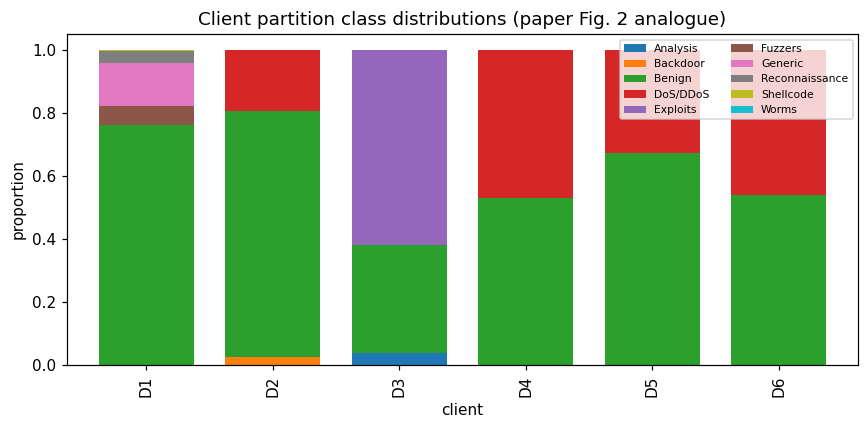

,D1,D2,D3,D4,D5,D6
category,,,,,,
Analysis,0,0,1610,0,0,0
Backdoor,0,473,0,0,0,0
Benign,13973,14184,14184,15442,15676,15676
DoS/DDoS,0,3520,0,13632,7624,13335
Exploits,0,0,25869,0,0,0
Fuzzers,1100,0,0,0,0,0
Generic,2479,0,0,0,0,0
Reconnaissance,676,0,0,0,0,0
Shellcode,82,0,0,0,0,0


In [14]:
CATEGORY_MAP = {'DoS': 'DoS/DDoS', 'DDoS': 'DoS/DDoS'}   # paper Section 3.2 category merge
def to_category(atk): return CATEGORY_MAP.get(atk, atk)

df_unsw['category']  = df_unsw['attack_type'].map(to_category)
df_cicids['category'] = df_cicids['attack_type'].map(to_category)
CLASSES = sorted(set(df_unsw['category'].unique()) | set(df_cicids['category'].unique()))
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASSES)}
BENIGN_IDX = CLASS_TO_IDX['Benign']
PARENT_N_CLASSES = {'UNSW': int(df_unsw['category'].nunique()), 'CICIDS': int(df_cicids['category'].nunique())}
print(f'{len(CLASSES)} categories: {CLASSES}')
print(f'parent dataset class counts (benign under-sampling denominators): {PARENT_N_CLASSES}')

for cid in CLIENT_IDS:
    parts_adv[cid] = parts_adv[cid].copy()
    parts_adv[cid]['category'] = parts_adv[cid]['attack_type'].map(to_category)
    parts_adv[cid]['mc_label'] = parts_adv[cid]['category'].map(CLASS_TO_IDX).astype(int)
for _d in (df_eval_clean, df_val):
    _d['category'] = _d['attack_type'].map(to_category)
    _d['mc_label'] = _d['category'].map(CLASS_TO_IDX).astype(int)

dist = pd.DataFrame({cid: parts_adv[cid]['category'].value_counts(normalize=True) for cid in CLIENT_IDS}).fillna(0)
ax = dist.T.plot(kind='bar', stacked=True, figsize=(8, 4), colormap='tab10', width=0.75)
ax.set_title('Client partition class distributions (paper Fig. 2 analogue)')
ax.set_ylabel('proportion'); ax.set_xlabel('client'); ax.legend(fontsize=7, ncol=2); plt.tight_layout(); plt.show()
display(pd.DataFrame({cid: parts_adv[cid]['category'].value_counts() for cid in CLIENT_IDS}).fillna(0).astype(int))

## Initial global-model training set (paper 3.2)

In [15]:
INIT_PER_CLASS = 1500

def build_initial_training_set(val_df, per_class=INIT_PER_CLASS, seed=SEED):
    mal_parts = [g.sample(n=min(len(g), per_class), random_state=seed)
                 for _, g in val_df[val_df['label'] == 1].groupby('category')]
    n_mal = sum(len(g) for g in mal_parts)
    ben = val_df[val_df['label'] == 0].sample(n=min(n_mal, (val_df['label'] == 0).sum()), random_state=seed)
    out = pd.concat(mal_parts + [ben]).sample(frac=1, random_state=seed)
    out['mc_label'] = out['category'].map(CLASS_TO_IDX).astype(int)
    return out

df_init = build_initial_training_set(df_val)
print(f'initial global-model training set: {len(df_init)} rows | benign={int((df_init.label==0).sum())} '
      f'| malicious={int((df_init.label==1).sum())}')
print(df_init['category'].value_counts())

initial global-model training set: 15100 rows | benign=7550 | malicious=7550
category
Benign            7550
DoS/DDoS          1500
Exploits          1500
Fuzzers           1500
Generic           1500
Reconnaissance    1049
Analysis           200
Backdoor           175
Shellcode          113
Worms               13
Name: count, dtype: int64


## Model architectures (paper 3.3, Figs. 3–4)

* **FcNN** — a **10-dense-layer** funnel (13 → 64 → 48 → 32 → 24 → 16 → 12 → 8 → 4 → 2 → classes), ReLU
  activations between layers. The narrow 2-unit bottleneck is faithful to the paper's deliberately simple
  edge-friendly design (and, as the paper's own results show, is exactly why the FcNN trails the 1dCNN).
* **1dCNN** — **alternating convolutional and pooling layers** (3 × [Conv1d → ReLU → MaxPool]), then flattening
  into a **200-unit dense layer** followed by the output dense layer (paper Fig. 4).

Both output one logit per category

In [16]:
class PaperFcNN(nn.Module):
    """FcNN with 10 dense layers (paper Fig. 3 analogue for 13 flow features)."""
    def __init__(self, input_dim=len(FEATURES), n_classes=len(CLASSES), dims=(64, 48, 32, 24, 16, 12, 8, 4, 2)):
        super().__init__()
        layers, prev = [], input_dim
        for h in dims:
            layers += [nn.Linear(prev, h), nn.ReLU()]
            prev = h
        layers.append(nn.Linear(prev, n_classes))           # 10th dense layer = output
        self.net = nn.Sequential(*layers)
    def forward(self, x): return self.net(x)

class Paper1dCNN(nn.Module):
    """1dCNN: alternating conv+pooling layers, flatten, 200-unit dense, output (paper Fig. 4)."""
    def __init__(self, input_dim=len(FEATURES), n_classes=len(CLASSES), channels=(32, 64, 128)):
        super().__init__()
        blocks, prev = [], 1
        for c in channels:
            blocks += [nn.Conv1d(prev, c, 3, padding=1), nn.ReLU(), nn.MaxPool1d(2)]
            prev = c
        self.convs = nn.Sequential(*blocks)
        with torch.no_grad():
            flat_dim = self.convs(torch.zeros(1, 1, input_dim)).flatten(1).shape[1]
        self.head = nn.Sequential(nn.Linear(flat_dim, 200), nn.ReLU(), nn.Linear(200, n_classes))
    def forward(self, x): return self.head(self.convs(x.unsqueeze(1)).flatten(1))

def make_model(kind): return PaperFcNN() if kind == 'fcnn' else Paper1dCNN()

def macs_estimate(model, input_dim=len(FEATURES)):
    """Multiply-accumulates per forward pass (Linear: in*out; Conv1d: k*cin*cout*L_out). ~2x this = FLOPs."""
    total = 0
    def probe(m, i, o):
        nonlocal total
        if isinstance(m, nn.Linear):   total += m.in_features * m.out_features
        elif isinstance(m, nn.Conv1d): total += m.out_channels * m.in_channels * m.kernel_size[0] * o.shape[-1]
    hooks = [m.register_forward_hook(probe) for m in model.modules() if isinstance(m, (nn.Linear, nn.Conv1d))]
    with torch.no_grad(): model(torch.zeros(1, input_dim))
    for h in hooks: h.remove()
    return total

model_facts = {}
rows = []
for kind, name in (('fcnn', 'FcNN'), ('1dcnn', '1dCNN')):
    m = make_model(kind)
    p = sum(q.numel() for q in m.parameters())
    model_facts[kind] = dict(params=p, size_MB=4 * p / 1e6, macs=macs_estimate(m))
    rows.append(dict(model=name, params=p, size_MB=round(4 * p / 1e6, 4),
                     MACs_per_inference=model_facts[kind]['macs'],
                     MFLOPs_per_inference=round(2 * model_facts[kind]['macs'] / 1e6, 4)))
display(pd.DataFrame(rows))

,model,params,size_MB,MACs_per_inference,MFLOPs_per_inference
0,FcNN,7160,0.0286,6940,0.0139
1,1dCNN,58850,0.2354,139440,0.2789


## FL aggregation algorithms (paper 3.1, Algorithms 1–2)

* **FedAvg / FedProx** — server takes the size-weighted average of the received client **weights** (Algorithm 1,
  line 7). FedProx clients add the (μ/2)·‖w−wₜ‖² **2-norm proximal penalty** with **μ = 1** (the paper's best
  configuration).
* **FedAdam / FedYogi / FedAdagrad** — clients run plain local SGD-style updates; the server takes an adaptive
  step on the mean pseudo-gradient Δₜ (Algorithm 2, lines 10–15) with β₁ = 0.9, β₂ = 0.99, τ = 10⁻³, η = 0.1
  (Flower/Reddi-style defaults).

In [17]:
class PaperServer:
    STRATEGIES = ('FedAvg', 'FedProx', 'FedAdam', 'FedYogi', 'FedAdagrad')
    def __init__(self, n_params, strategy, beta1=0.9, beta2=0.99, eta=0.1, tau=1e-3):
        assert strategy in self.STRATEGIES, strategy
        self.strategy, self.beta1, self.beta2, self.eta, self.tau = strategy, beta1, beta2, eta, tau
        self.m_t = torch.zeros(n_params)
        self.v_t = torch.ones(n_params) * (tau ** 2)

    def aggregate(self, global_flat, client_flats, sizes):
        if self.strategy in ('FedAvg', 'FedProx'):            
            w = torch.tensor(sizes, dtype=torch.float32); w = w / w.sum()
            return (w[:, None] * torch.stack(client_flats)).sum(0)
        delta = (torch.stack(client_flats) - global_flat).mean(0)  
        self.m_t = self.beta1 * self.m_t + (1 - self.beta1) * delta
        sq = delta ** 2
        if self.strategy == 'FedAdam':      self.v_t = self.beta2 * self.v_t + (1 - self.beta2) * sq
        elif self.strategy == 'FedYogi':    self.v_t = self.v_t - (1 - self.beta2) * sq * torch.sign(self.v_t - sq)
        elif self.strategy == 'FedAdagrad': self.v_t = self.v_t + sq
        return global_flat + self.eta * self.m_t / (self.v_t.sqrt() + self.tau)

def client_update_paper(model, global_flat, df, local_epochs=LOCAL_EPOCHS, lr=LR,
                        batch_size=BATCH_SIZE, mu=0.0):
    """Algorithm 1 ClientUpdate: E local epochs of Adam on cross-entropy; FedProx adds the
    (mu/2)||w - w_t||^2 proximal penalty on the 2-norm."""
    load_flat(model, global_flat); model.train()
    anchors = [q.detach().clone() for q in model.parameters()]
    X = torch.tensor(df[FEATURES].values, dtype=torch.float32)
    y = torch.tensor(df['mc_label'].values.astype(np.int64))
    loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(X, y), batch_size=batch_size, shuffle=True)
    opt, crit = optim.Adam(model.parameters(), lr=lr), nn.CrossEntropyLoss()
    for _ in range(local_epochs):
        for xb, yb in loader:
            opt.zero_grad()
            loss = crit(model(xb), yb)
            if mu > 0:
                loss = loss + 0.5 * mu * sum(((q - a) ** 2).sum() for q, a in zip(model.parameters(), anchors))
            loss.backward(); opt.step()
    return flat_of(model)

@torch.no_grad()
def predict_mc(model, df, batch=16384):
    model.eval()
    X = torch.tensor(df[FEATURES].values, dtype=torch.float32)
    logits = np.concatenate([model(X[i:i + batch]).numpy() for i in range(0, len(X), batch)])
    e = np.exp(logits - logits.max(1, keepdims=True))
    prob = e / e.sum(1, keepdims=True)
    return prob.argmax(1).astype(int), prob

## Static evaluation set + full metric suite (paper 3.4, Table 2)

Every metric of the paper's Table 2 is computed **after every round** on the static evaluation set:
multi-class accuracy, **balanced accuracy** (Eq. 1 — the mean of per-class recalls), binary accuracy, binary
balanced accuracy, weighted recall/precision/F1, macro F1 and **Cohen's Kappa** (Eq. 2), plus MCC and AUC extras
and the binary-side metrics used for the head-to-head comparison with the advanced pipeline.

In [18]:
def table2_metrics(y_mc, pred_mc, prob=None):
    """Paper Table 2 metric suite on multi-class predictions. Binary views collapse
    'everything that is not Benign' into the malicious class."""
    y_mc, pred_mc = np.asarray(y_mc), np.asarray(pred_mc)
    y_bin, p_bin = (y_mc != BENIGN_IDX).astype(int), (pred_mc != BENIGN_IDX).astype(int)
    out = dict(
        mc_acc=accuracy_score(y_mc, pred_mc),
        mc_bal_acc=balanced_accuracy_score(y_mc, pred_mc),                       
        bin_acc=accuracy_score(y_bin, p_bin),
        bin_bal_acc=balanced_accuracy_score(y_bin, p_bin),
        w_recall=recall_score(y_mc, pred_mc, average='weighted', zero_division=0),
        w_precision=precision_score(y_mc, pred_mc, average='weighted', zero_division=0),
        w_f1=f1_score(y_mc, pred_mc, average='weighted', zero_division=0),
        macro_f1=f1_score(y_mc, pred_mc, average='macro', zero_division=0),
        kappa=cohen_kappa_score(y_mc, pred_mc),                                  
        mcc=matthews_corrcoef(y_mc, pred_mc) if len(set(pred_mc)) > 1 else 0.0,
        bin_f1=f1_score(y_bin, p_bin, zero_division=0),
        bin_precision=precision_score(y_bin, p_bin, zero_division=0),
        bin_recall=recall_score(y_bin, p_bin, zero_division=0),
        bin_kappa=cohen_kappa_score(y_bin, p_bin))
    if prob is not None and len(np.unique(y_bin)) == 2:
        out['bin_auc'] = roc_auc_score(y_bin, 1.0 - prob[:, BENIGN_IDX])
    return out

print('evaluation set (static, scored every round):', len(df_eval_clean), 'rows |',
      df_eval_clean['category'].value_counts().to_dict())

evaluation set (static, scored every round): 40107 rows | {'Benign': 15369, 'DoS/DDoS': 14029, 'Generic': 4000, 'Exploits': 3340, 'Fuzzers': 1819, 'Reconnaissance': 1049, 'Analysis': 200, 'Backdoor': 175, 'Shellcode': 113, 'Worms': 13}


## Per-round client sampling (paper 3.2 — the data-efficiency mechanism)

Each round, every client draws **at most 5,000 samples** from its partition: a stratified draw across the classes
present on that client (sampled **with replacement**, as in the paper), after which the **benign class is
under-sampled to** `n_malicious / (n_classes_of_parent_dataset − 1)` — e.g. ÷9 for the UNSW clients (10 parent
categories) and ÷1 for the CICIDS clients (2 parent categories). Each round therefore simulates a fresh day of
local network traffic.

In [19]:
def paper_round_sample(df, n_max=N_SAMPLES_PER_ROUND, parent_n_classes=None, seed=SEED):
    parent_n_classes = parent_n_classes or PARENT_N_CLASSES
    dom = df['source_domain'].iloc[0]
    per_class = max(1, n_max // max(1, df['category'].nunique()))
    mal_parts = [g.sample(n=max(1, min(len(g), per_class)), replace=True, random_state=seed)
                 for _, g in df[df['label'] == 1].groupby('category')]
    mal = pd.concat(mal_parts)
    ben_pool = df[df['label'] == 0]
    ben = ben_pool.sample(n=max(1, min(len(ben_pool), per_class)), replace=True, random_state=seed)
    ben_target = max(1, int(round(len(mal) / (parent_n_classes[dom] - 1))))     
    if len(ben) > ben_target:
        ben = ben.sample(n=ben_target, replace=False, random_state=seed)
    return pd.concat([mal, ben])

for cid in CLIENT_IDS:
    s = paper_round_sample(parts_adv[cid], seed=1)
    print(f'{cid} round draw: {len(s):>5} rows | benign={int((s.label==0).sum()):>5} | '
          f'malicious={int((s.label==1).sum()):>5} | parent classes={PARENT_N_CLASSES[CLIENT_DOMAIN[cid]]}')

D1 round draw:  2702 rows | benign=  270 | malicious= 2432 | parent classes=10
D2 round draw:  2377 rows | benign=  238 | malicious= 2139 | parent classes=10
D3 round draw:  3640 rows | benign=  364 | malicious= 3276 | parent classes=10
D4 round draw:  5000 rows | benign= 2500 | malicious= 2500 | parent classes=2
D5 round draw:  5000 rows | benign= 2500 | malicious= 2500 | parent classes=2
D6 round draw:  5000 rows | benign= 2500 | malicious= 2500 | parent classes=2


## Centrally-trained baseline (paper Table 1, "Baseline" rows)

The paper contrasts FL against a **centrally trained** model: all client data must be shipped to the server once
(raw-data transfer) and the full model shipped back. Here the baseline trains the same architecture on the pooled
union of one paper-style per-round draw from every client, for the same total number of epochs
(`ROUNDS × LOCAL_EPOCHS`), and is scored with the same metric suite every 5 epochs.

In [20]:
def run_centralized(model_kind, rounds=ROUNDS, local_epochs=LOCAL_EPOCHS, seed=SEED):
    set_seed(seed)
    pooled = pd.concat([paper_round_sample(parts_adv[cid], seed=seed + 100 + i)
                        for i, cid in enumerate(CLIENT_IDS)])
    model = make_model(model_kind)
    opt, crit = optim.Adam(model.parameters(), lr=LR), nn.CrossEntropyLoss()
    X = torch.tensor(pooled[FEATURES].values, dtype=torch.float32)
    y = torch.tensor(pooled['mc_label'].values.astype(np.int64))
    loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(X, y), batch_size=BATCH_SIZE, shuffle=True)
    history = []
    t0 = time.time()
    for ep in range(1, rounds * local_epochs + 1):
        model.train()
        for xb, yb in loader:
            opt.zero_grad(); crit(model(xb), yb).backward(); opt.step()
        if ep % local_epochs == 0:
            pred, prob = predict_mc(model, df_eval_clean)
            history.append(dict(epoch=ep, **table2_metrics(df_eval_clean['mc_label'].values, pred, prob)))
    wall = time.time() - t0
    data_MB = len(pooled) * len(FEATURES) * 4 / 1e6           
    model_MB = 4 * sum(q.numel() for q in model.parameters()) / 1e6
    return dict(model=model, history=pd.DataFrame(history), wall_s=wall,
                data_MB=data_MB, model_MB=model_MB, n_train=len(pooled), model_kind=model_kind)

## The paper's federated loop (4)

1. The server pre-trains the **initial global model** centrally on the balanced combined set and broadcasts it.
2. Each (selected) client draws a fresh **paper-style round sample**, trains **E = 5 local epochs**, and ships its
   **full FP32 weights** (bytes are counted — this is the per-round bandwidth of Table 1).
3. The server aggregates per the selected strategy and the updated global model is evaluated on the **static
   evaluation set with the full Table-2 metric suite** — every round.
4. `min_clients < 6` switches the run into the paper's **asynchronous** mode (a random subset of that many
   clients participates each round).

In [21]:
def run_paper_fl(model_kind='1dcnn', strategy='FedProx', rounds=ROUNDS, min_clients=None,
                 local_epochs=LOCAL_EPOCHS, n_samples=N_SAMPLES_PER_ROUND, mu=None, seed=SEED,
                 init_epochs=INIT_EPOCHS, verbose=True, tag=''):
    if mu is None: mu = FEDPROX_MU if strategy == 'FedProx' else 0.0
    set_seed(seed)
    gm = make_model(model_kind)
    n_params = sum(q.numel() for q in gm.parameters())
    server = PaperServer(n_params, strategy)

    t0 = time.time()
    opt, crit = optim.Adam(gm.parameters(), lr=LR), nn.CrossEntropyLoss()
    Xi = torch.tensor(df_init[FEATURES].values, dtype=torch.float32)
    yi = torch.tensor(df_init['mc_label'].values.astype(np.int64))
    loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(Xi, yi), batch_size=BATCH_SIZE, shuffle=True)
    for _ in range(init_epochs):
        gm.train()
        for xb, yb in loader:
            opt.zero_grad(); crit(gm(xb), yb).backward(); opt.step()
    init_time = time.time() - t0

    y_eval = df_eval_clean['mc_label'].values
    pred0, prob0 = predict_mc(gm, df_eval_clean)
    history = [dict(round=0, **{k: round(v, 4) for k, v in table2_metrics(y_eval, pred0, prob0).items()},
                    round_train_s=0.0, round_s=0.0, cum_MB=0.0)]
    up_bytes = down_bytes = 0
    n_active = len(CLIENT_IDS) if min_clients is None else min_clients

    for r in range(1, rounds + 1):
        t_round = time.time()
        rng = np.random.RandomState(seed * 1000 + r)
        chosen = CLIENT_IDS if min_clients is None else list(rng.choice(CLIENT_IDS, size=min_clients, replace=False))
        flats, sizes, t_clients = [], [], 0.0
        for i, cid in enumerate(chosen):
            df_s = paper_round_sample(parts_adv[cid], n_samples, seed=seed * 1000 + 100 * r + i)
            tc = time.time()
            flats.append(client_update_paper(copy.deepcopy(gm), flat_of(gm), df_s, local_epochs, mu=mu))
            t_clients += time.time() - tc
            sizes.append(len(df_s))
            up_bytes += 4 * n_params                       
        load_flat(gm, server.aggregate(flat_of(gm), flats, sizes))
        down_bytes += 4 * n_params * len(chosen)           
        pred, prob = predict_mc(gm, df_eval_clean)
        m = table2_metrics(y_eval, pred, prob)
        history.append(dict(round=r, **{k: round(v, 4) for k, v in m.items()},
                            round_train_s=round(t_clients, 3), round_s=round(time.time() - t_round, 3),
                            cum_MB=round((up_bytes + down_bytes) / 1e6, 4)))
        if verbose and (r % 5 == 0 or r == rounds):
            print(f'  [{tag}] round {r:>3}/{rounds} | mc_acc {m["mc_acc"]:.4f} | mc_bal_acc {m["mc_bal_acc"]:.4f} '
                  f'| bin_acc {m["bin_acc"]:.4f} | kappa {m["kappa"]:.4f}')
    return dict(model=gm, history=pd.DataFrame(history), strategy=strategy, model_kind=model_kind,
                n_params=n_params, model_MB=4 * n_params / 1e6, up_bytes=up_bytes, down_bytes=down_bytes,
                bytes_per_round=4 * n_params * n_active * 2, init_time_s=init_time, mu=mu,
                rounds=rounds, min_clients=min_clients, seed=seed)

## Experiment grid: 2 models × 5 FL algorithms × N_RUNS (paper 5.1)

The paper repeated each combination 30× to get mean ± std over the random per-round sampling; set `N_RUNS = 30`
to fully reproduce. Progress prints every 5 rounds of the first run of each combination.

In [22]:
t0 = time.time()
grid_results = []
for model_kind in ('fcnn', '1dcnn'):
    for strategy in PaperServer.STRATEGIES:
        for run in range(1, N_RUNS + 1):
            res = run_paper_fl(model_kind, strategy, rounds=ROUNDS, seed=SEED + run,
                               verbose=(run == 1), tag=f'{model_kind}/{strategy}/run{run}')
            h = res['history'].assign(model=model_kind, strategy=strategy, run=run)
            grid_results.append((res, h))
            print(f'== {model_kind}/{strategy} run {run}/{N_RUNS} done | final kappa '
                  f'{float(h.iloc[-1]["kappa"]):.4f} | {time.time() - t0:.0f}s elapsed')

fl_long = pd.concat([h for _, h in grid_results], ignore_index=True)
grid_meta = pd.DataFrame([dict(model=r['model_kind'], strategy=r['strategy'], run=i + 1,
                               params=r['n_params'], model_MB=round(r['model_MB'], 4),
                               MB_per_round=round(r['bytes_per_round'] / 1e6, 4),
                               avg_client_train_s=round(float(r['history']['round_train_s'][1:].mean()), 3),
                               avg_round_s=round(float(r['history']['round_s'][1:].mean()), 3),
                               init_time_s=round(r['init_time_s'], 2))
                          for i, (r, _) in enumerate(grid_results)])
display(grid_meta.groupby(['model', 'strategy']).mean(numeric_only=True).drop(columns='run').round(3))

  [fcnn/FedAvg/run1] round   5/30 | mc_acc 0.3832 | mc_bal_acc 0.1000 | bin_acc 0.3832 | kappa 0.0000
  [fcnn/FedAvg/run1] round  10/30 | mc_acc 0.3832 | mc_bal_acc 0.1000 | bin_acc 0.3832 | kappa 0.0000
  [fcnn/FedAvg/run1] round  15/30 | mc_acc 0.3832 | mc_bal_acc 0.1000 | bin_acc 0.3832 | kappa 0.0000
  [fcnn/FedAvg/run1] round  20/30 | mc_acc 0.3498 | mc_bal_acc 0.1000 | bin_acc 0.6168 | kappa 0.0000
  [fcnn/FedAvg/run1] round  25/30 | mc_acc 0.3498 | mc_bal_acc 0.1000 | bin_acc 0.6168 | kappa 0.0000
  [fcnn/FedAvg/run1] round  30/30 | mc_acc 0.3498 | mc_bal_acc 0.1000 | bin_acc 0.6168 | kappa 0.0000
== fcnn/FedAvg run 1/3 done | final kappa 0.0000 | 86s elapsed
== fcnn/FedAvg run 2/3 done | final kappa 0.4140 | 174s elapsed
== fcnn/FedAvg run 3/3 done | final kappa 0.4750 | 264s elapsed
  [fcnn/FedProx/run1] round   5/30 | mc_acc 0.3832 | mc_bal_acc 0.1000 | bin_acc 0.3832 | kappa 0.0000
  [fcnn/FedProx/run1] round  10/30 | mc_acc 0.3832 | mc_bal_acc 0.1000 | bin_acc 0.3832 | kapp

params  model_MB  MB_per_round  avg_client_train_s  \
model strategy                                                          
1dcnn FedAdagrad  58850.0     0.235         2.825               6.240   
      FedAdam     58850.0     0.235         2.825               6.287   
      FedAvg      58850.0     0.235         2.825               6.911   
      FedProx     58850.0     0.235         2.825               7.066   
      FedYogi     58850.0     0.235         2.825               6.317   
fcnn  FedAdagrad   7160.0     0.029         0.344               2.400   
      FedAdam      7160.0     0.029         0.344               2.475   
      FedAvg       7160.0     0.029         0.344               2.670   
      FedProx      7160.0     0.029         0.344               3.496   
      FedYogi      7160.0     0.029         0.344               2.414   

                  avg_round_s  init_time_s  
model strategy                              
1dcnn FedAdagrad        6.559        7.807  
      FedAdam           6.605        7.913  
      FedAvg            7.250        8.620  
      FedProx           7.391        8.240  
      FedYogi           6.637        7.970  
fcnn  FedAdagrad        2.501        3.000  
      FedAdam           2.574        3.007  
      FedAvg            2.779        4.387  
      FedProx           3.598        3.210  
      FedYogi           2.512        3.053

## Final-round classification metrics (paper Table 2 reproduction)

Mean over runs at the final round; **bold = best** model/algorithm per metric, exactly as in the paper's Table 2.

In [23]:
METRIC_COLS = ['mc_acc', 'mc_bal_acc', 'bin_acc', 'bin_bal_acc', 'w_recall', 'w_precision', 'w_f1',
               'macro_f1', 'kappa', 'mcc', 'bin_f1', 'bin_precision', 'bin_recall', 'bin_kappa', 'bin_auc']
PRETTY = dict(mc_acc='Multi-class Acc.', mc_bal_acc='Multi-class Bal. Acc.', bin_acc='Binary Acc.',
              bin_bal_acc='Binary Bal. Acc.', w_recall='Wtd. Recall', w_precision='Wtd. Precision',
              w_f1='Wtd. F1-Score', macro_f1='Macro F1-Score', kappa='Kappa', mcc='MCC', bin_f1='Binary F1',
              bin_precision='Binary Precision', bin_recall='Binary Recall', bin_kappa='Binary Kappa',
              bin_auc='Binary AUC')
final = fl_long[fl_long['round'] == ROUNDS]
table2 = final.groupby(['model', 'strategy'])[METRIC_COLS].mean().round(4)
table2.columns = [PRETTY[c] for c in table2.columns]
table2 = table2[[PRETTY[c] for c in ['mc_acc', 'mc_bal_acc', 'bin_acc', 'bin_bal_acc', 'w_recall',
                                     'w_precision', 'w_f1', 'macro_f1', 'kappa', 'mcc']]]
display(table2.style.apply(lambda col: ['font-weight: bold' if v == col.max() else '' for v in col]))
table2.to_csv('paper_table2_results.csv')
print('saved paper_table2_results.csv')

saved paper_table2_results.csv


## Best-combination deep dive 

ROC / precision-recall on the binary view, per-class recall, and per-round cost for the best model/algorithm
combination found in Table 2.

best combination by Kappa: ('1dcnn', 'FedProx')


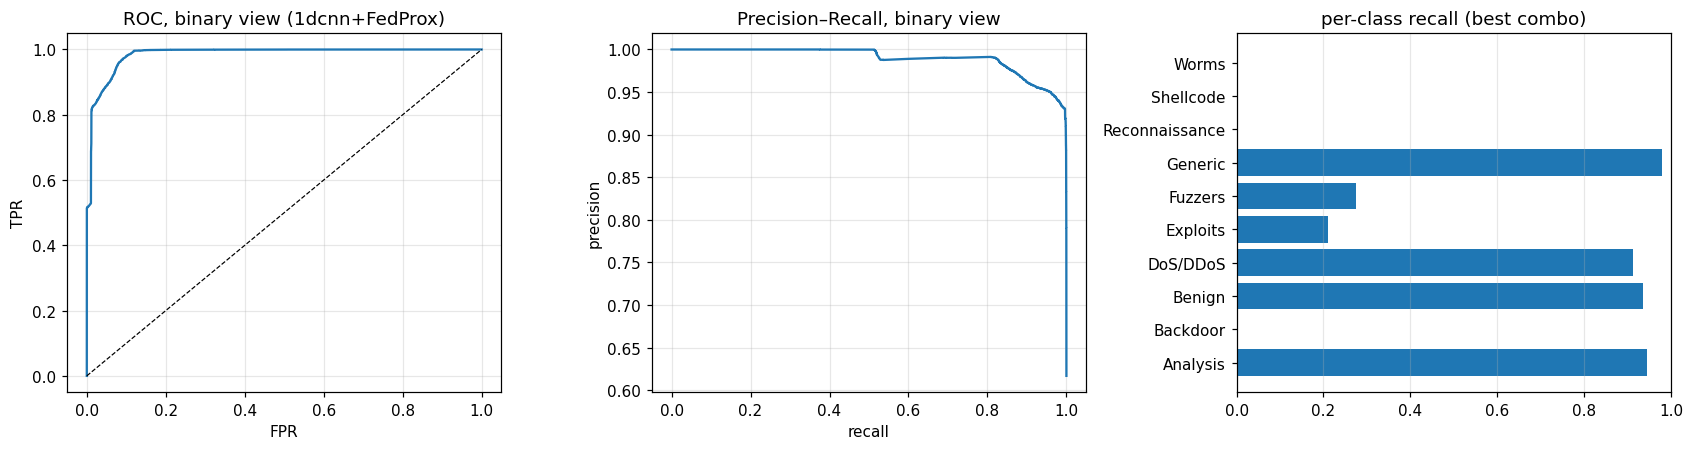

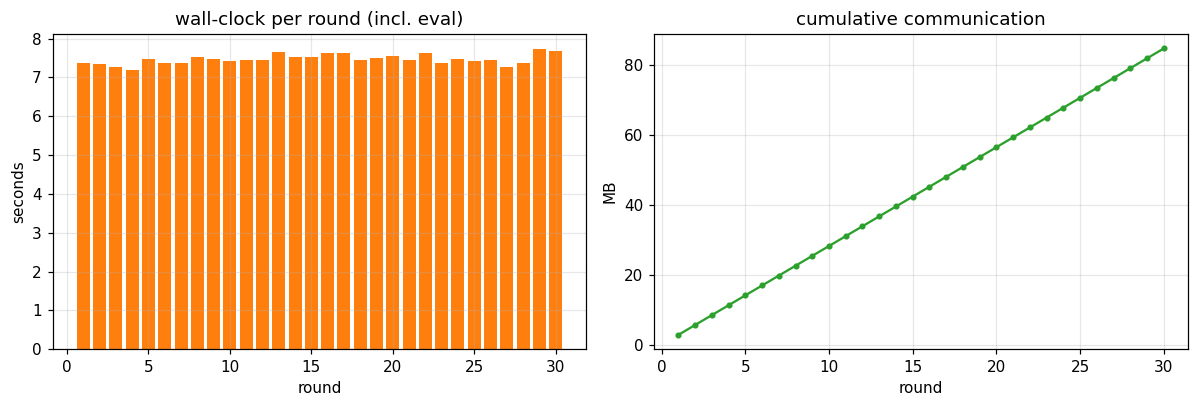

In [24]:
from sklearn.metrics import roc_curve, precision_recall_curve
best_combo_key = table2['Kappa'].idxmax()
best_mk, best_st = best_combo_key
print('best combination by Kappa:', best_combo_key)
best_run = next(r for r, h in grid_results if r['model_kind'] == best_mk and r['strategy'] == best_st)
pred_b, prob_b = predict_mc(best_run['model'], df_eval_clean)
y_bin_ev = (df_eval_clean['mc_label'].values != BENIGN_IDX).astype(int)
score_b = 1.0 - prob_b[:, BENIGN_IDX]
fpr_b, tpr_b, _ = roc_curve(y_bin_ev, score_b)
prec_b, rec_b, _ = precision_recall_curve(y_bin_ev, score_b)
rec_pc = recall_score(df_eval_clean['mc_label'].values, pred_b, labels=range(len(CLASSES)),
                      average=None, zero_division=0)
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.2))
axes[0].plot(fpr_b, tpr_b); axes[0].plot([0, 1], [0, 1], 'k--', lw=0.8)
axes[0].set_title(f'ROC, binary view ({best_mk}+{best_st})'); axes[0].set_xlabel('FPR'); axes[0].set_ylabel('TPR')
axes[0].grid(alpha=0.3)
axes[1].plot(rec_b, prec_b); axes[1].set_title('Precision–Recall, binary view')
axes[1].set_xlabel('recall'); axes[1].set_ylabel('precision'); axes[1].grid(alpha=0.3)
axes[2].barh(CLASSES, rec_pc, color='tab:blue'); axes[2].set_xlim(0, 1)
axes[2].set_title('per-class recall (best combo)'); axes[2].grid(alpha=0.3, axis='x')
fig.tight_layout(); plt.show()

bh = best_run['history']
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].bar(bh['round'][1:], bh['round_s'][1:], color='tab:orange')
axes[0].set_xlabel('round'); axes[0].set_ylabel('seconds'); axes[0].set_title('wall-clock per round (incl. eval)')
axes[0].grid(alpha=0.3)
axes[1].plot(bh['round'][1:], bh['cum_MB'][1:], color='tab:green', marker='o', ms=3)
axes[1].set_xlabel('round'); axes[1].set_ylabel('MB'); axes[1].set_title('cumulative communication')
axes[1].grid(alpha=0.3)
fig.tight_layout(); plt.show()

## Complexity analysis (paper Table 1 reproduction)

Time per round (measured client training + aggregation wall-clock), bandwidth per round (full FP32 weights,
up + down, all participating clients), model parameters / size / MACs, plus the **centrally-trained baseline**
whose communication cost is shipping the pooled raw data to the server once. `avg_round_s` additionally includes
the per-round evaluation pass.

,Model,Algorithm,Params,Size_MB,MACs,Time_per_round_s,MB_per_round,Total_comm_MB,Final_Kappa
0,FcNN,Baseline,7160,0.0286,6940,2.688,-,1.262,0.7728
1,FcNN,FedAdagrad,7160,0.0286,6940,2.400,0.3437,10.311,0.2924
2,FcNN,FedAdam,7160,0.0286,6940,2.475,0.3437,10.311,0.0000
3,FcNN,FedAvg,7160,0.0286,6940,2.670,0.3437,10.311,0.2963
4,FcNN,FedProx,7160,0.0286,6940,3.496,0.3437,10.311,0.3122
5,FcNN,FedYogi,7160,0.0286,6940,2.414,0.3437,10.311,0.0005
6,1dCNN,Baseline,58850,0.2354,139440,6.906,-,1.469,0.8391
7,1dCNN,FedAdagrad,58850,0.2354,139440,6.240,2.8248,84.744,0.5246
8,1dCNN,FedAdam,58850,0.2354,139440,6.287,2.8248,84.744,0.3105
9,1dCNN,FedAvg,58850,0.2354,139440,6.911,2.8248,84.744,0.5453


saved paper_table1_complexity.csv


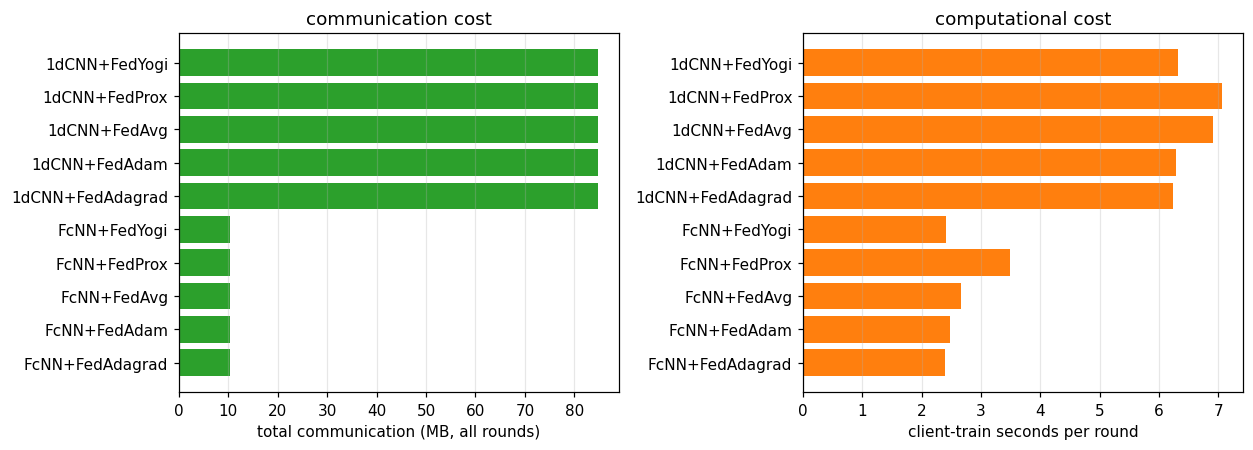

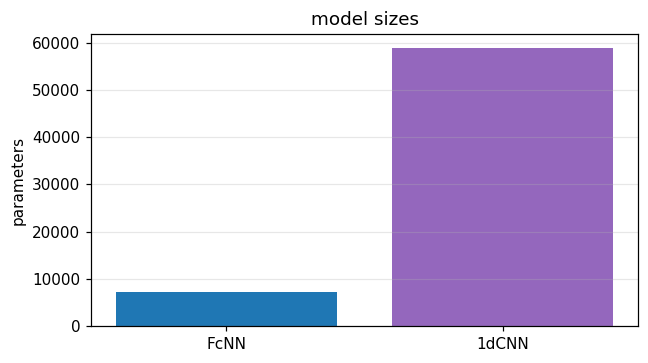

In [25]:
rows = []
for model_kind, mname in (('fcnn', 'FcNN'), ('1dcnn', '1dCNN')):
    base = run_centralized(model_kind, rounds=ROUNDS)
    last = base['history'].iloc[-1]
    rows.append(dict(Model=mname, Algorithm='Baseline',
                     Params=model_facts[model_kind]['params'],
                     Size_MB=round(model_facts[model_kind]['size_MB'], 4),
                     MACs=model_facts[model_kind]['macs'],
                     Time_per_round_s=round(base['wall_s'] / ROUNDS, 3),
                     MB_per_round='-', Total_comm_MB=round(base['data_MB'] + base['model_MB'], 3),
                     Final_Kappa=round(float(last['kappa']), 4)))
    sub = grid_meta[grid_meta['model'] == model_kind].groupby('strategy').mean(numeric_only=True)
    fin = final[final['model'] == model_kind].groupby('strategy')['kappa'].mean()
    for strategy, r in sub.iterrows():
        rows.append(dict(Model=mname, Algorithm=strategy,
                         Params=model_facts[model_kind]['params'],
                         Size_MB=round(model_facts[model_kind]['size_MB'], 4),
                         MACs=model_facts[model_kind]['macs'],
                         Time_per_round_s=round(r['avg_client_train_s'], 3),
                         MB_per_round=round(r['MB_per_round'], 4),
                         Total_comm_MB=round(r['MB_per_round'] * ROUNDS, 3),
                         Final_Kappa=round(float(fin[strategy]), 4)))
table1 = pd.DataFrame(rows)
display(table1)
table1.to_csv('paper_table1_complexity.csv', index=False)
print('saved paper_table1_complexity.csv')

fl1 = table1[table1['Algorithm'] != 'Baseline']
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
axes[0].barh([f'{r.Model}+{r.Algorithm}' for r in fl1.itertuples()], fl1['Total_comm_MB'], color='tab:green')
axes[0].set_xlabel('total communication (MB, all rounds)'); axes[0].set_title('communication cost')
axes[0].grid(alpha=0.3, axis='x')
axes[1].barh([f'{r.Model}+{r.Algorithm}' for r in fl1.itertuples()], fl1['Time_per_round_s'], color='tab:orange')
axes[1].set_xlabel('client-train seconds per round'); axes[1].set_title('computational cost')
axes[1].grid(alpha=0.3, axis='x')
fig.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(6, 3.4))
ax.bar(['FcNN', '1dCNN'], [model_facts['fcnn']['params'], model_facts['1dcnn']['params']],
       color=['tab:blue', 'tab:purple'])
ax.set_ylabel('parameters'); ax.set_title('model sizes'); ax.grid(alpha=0.3, axis='y')
plt.tight_layout(); plt.show()

## Per-round convergence (paper Figs. 6–8 reproduction)

Mean over runs per round with a **±1 standard-deviation band**, for multi-class accuracy (Fig. 6), balanced
accuracy (Fig. 7) and Cohen's Kappa (Fig. 8) — FcNN on the left, 1dCNN on the right, one line per FL algorithm.

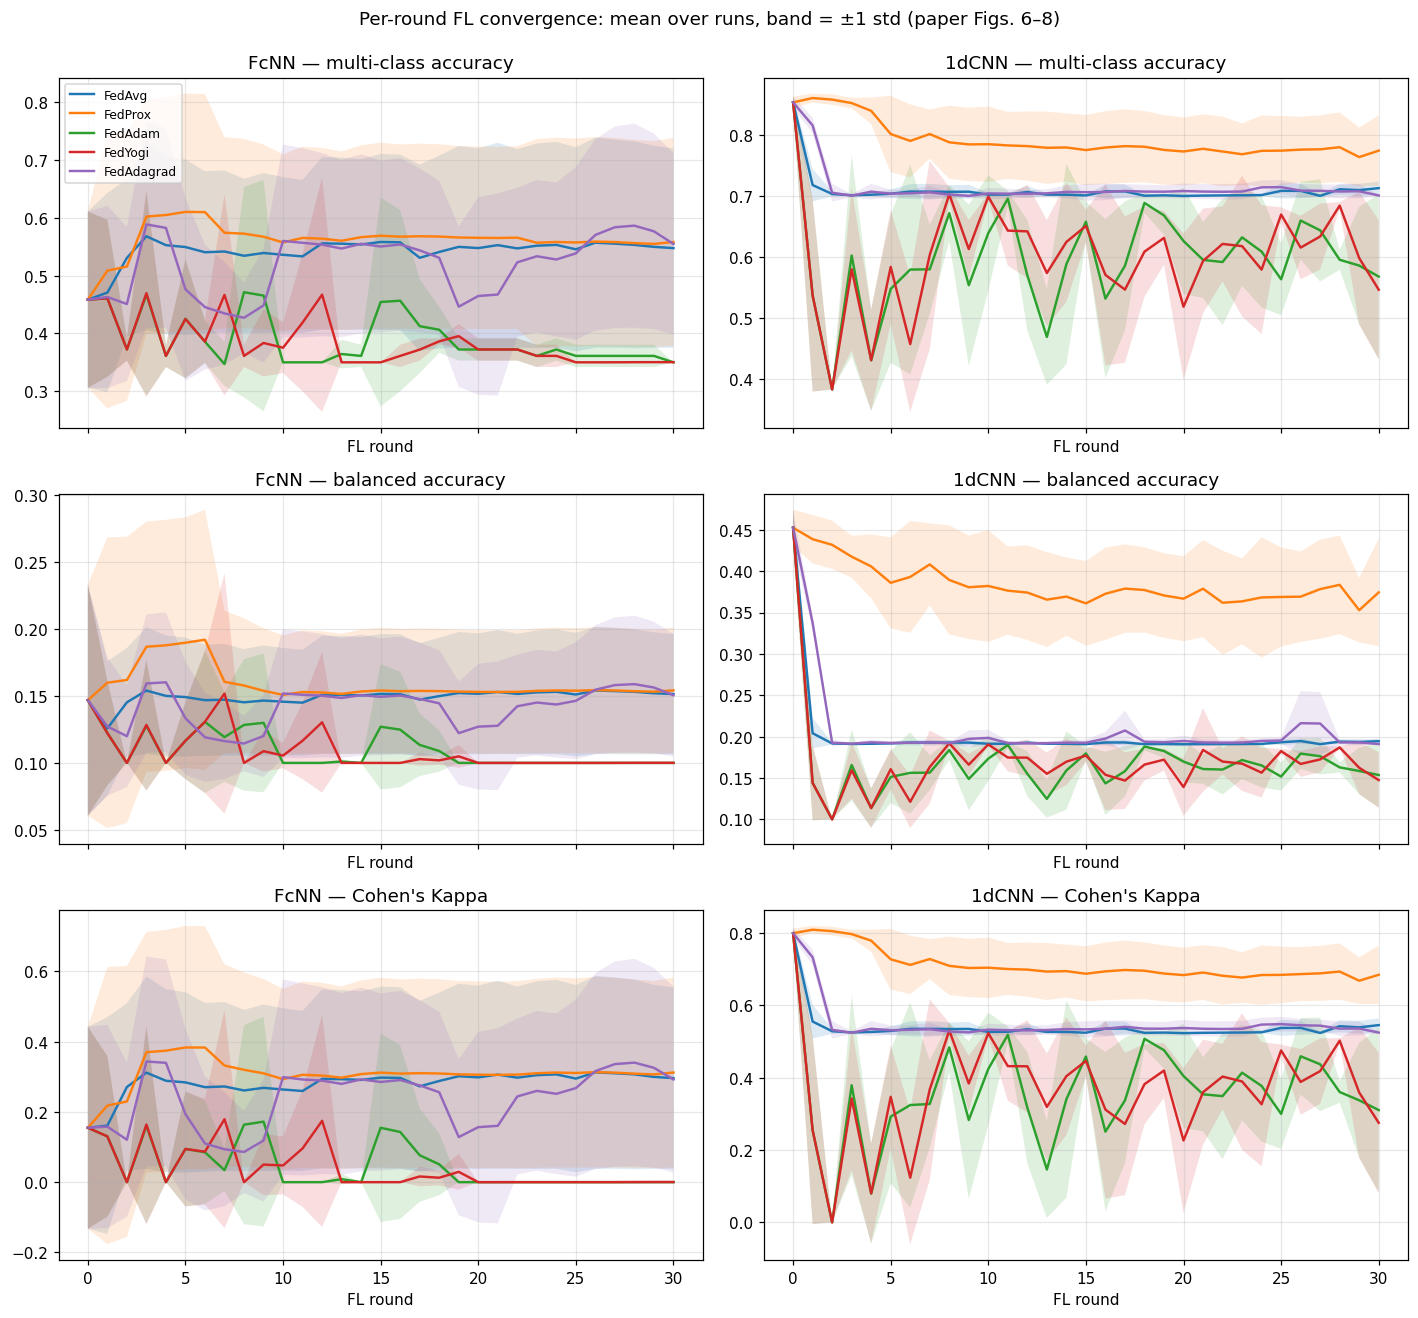

In [26]:
TITLES = dict(mc_acc='multi-class accuracy', mc_bal_acc='balanced accuracy', kappa="Cohen's Kappa")
fig, axes = plt.subplots(3, 2, figsize=(13, 12), sharex=True)
for j, model_kind in enumerate(('fcnn', '1dcnn')):
    for i, metric in enumerate(('mc_acc', 'mc_bal_acc', 'kappa')):
        ax = axes[i, j]
        for strategy in PaperServer.STRATEGIES:
            sub = fl_long[(fl_long['model'] == model_kind) & (fl_long['strategy'] == strategy)]
            g = sub.groupby('round')[metric]
            mean, std = g.mean(), g.std()
            ax.plot(mean.index, mean.values, label=strategy, lw=1.6)
            ax.fill_between(mean.index, mean - std, mean + std, alpha=0.15)
        ax.set_title(f'{"FcNN" if model_kind == "fcnn" else "1dCNN"} — {TITLES[metric]}')
        ax.set_xlabel('FL round'); ax.grid(alpha=0.3)
axes[0, 0].legend(fontsize=8)
fig.suptitle('Per-round FL convergence: mean over runs, band = ±1 std (paper Figs. 6–8)', y=0.995)
fig.tight_layout(); fig.savefig('paper_figs6-8_convergence.png', dpi=130); plt.show()

## Asynchronous FL (paper 5.2)

Using the best model/algorithm combination measured above (the paper used 1dCNN + FedProx), each round only a
random subset of `k ∈ {2..6}` clients participates. The paper's finding — results saturate once **at least ~4 of
6 clients** (two-thirds) participate — is checked with the same metrics (paper Figs. 9–11).

best combination by Cohen's Kappa: 1dcnn + FedProx


,mc_acc,mc_bal_acc,bin_acc,kappa
min_clients,,,,
2,0.7602,0.3086,0.9226,0.6424
3,0.7988,0.4186,0.9422,0.7238
4,0.7710,0.3834,0.9466,0.6861
5,0.7994,0.4115,0.9356,0.7214
6,0.8020,0.4160,0.9462,0.7272


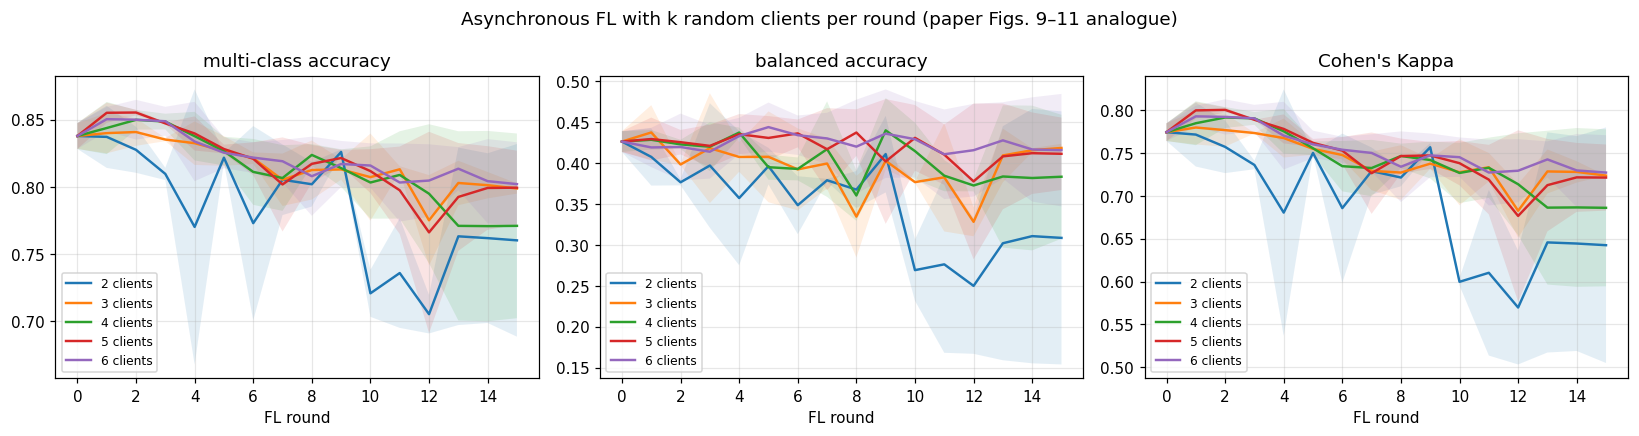

In [27]:
best_model, best_strategy = final.groupby(['model', 'strategy'])['kappa'].mean().idxmax()
print(f"best combination by Cohen's Kappa: {best_model} + {best_strategy}")

async_rows = []
for k in range(2, len(CLIENT_IDS) + 1):
    for run in range(1, N_ASYNC_RUNS + 1):
        res = run_paper_fl(best_model, best_strategy, rounds=ASYNC_ROUNDS, min_clients=k,
                           seed=SEED + 200 + run, verbose=False, tag=f'async k={k}')
        async_rows.append(res['history'].assign(min_clients=k, run=run))
async_long = pd.concat(async_rows, ignore_index=True)

async_final = async_long[async_long['round'] == ASYNC_ROUNDS].groupby('min_clients')[
    ['mc_acc', 'mc_bal_acc', 'bin_acc', 'kappa']].mean().round(4)
display(async_final)

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True)
for ax, metric in zip(axes, ('mc_acc', 'mc_bal_acc', 'kappa')):
    for k in sorted(async_long['min_clients'].unique()):
        g = async_long[async_long['min_clients'] == k].groupby('round')[metric]
        ax.plot(g.mean().index, g.mean().values, label=f'{k} clients', lw=1.6)
        ax.fill_between(g.mean().index, g.mean() - g.std(), g.mean() + g.std(), alpha=0.12)
    ax.set_title(TITLES[metric]); ax.set_xlabel('FL round'); ax.grid(alpha=0.3); ax.legend(fontsize=8)
fig.suptitle('Asynchronous FL with k random clients per round (paper Figs. 9–11 analogue)')
fig.tight_layout(); fig.savefig('paper_figs9-11_async.png', dpi=130); plt.show()

## Epoch-budget experiments: 5 vs 10 local epochs

Every model × algorithm combination retrained with **E = 5 vs E = 10 local epochs** per round (fixed 10-round
budget, all other hyper-parameters per the paper's defaults) — the same epoch-budget comparison the baseline and
advanced notebooks run, scored with the full metric suite at the final round.

In [28]:
EPOCH_SWEEP_ROUNDS = 10
PAPER_EPOCH_BUDGETS = (5, 10)
paper_epoch_rows, paper_epoch_frames = [], []
t0 = time.time()
for mk in ('fcnn', '1dcnn'):
    for st in PaperServer.STRATEGIES:
        for ep in PAPER_EPOCH_BUDGETS:
            res = run_paper_fl(mk, st, rounds=EPOCH_SWEEP_ROUNDS, local_epochs=ep, seed=SEED + 300,
                               verbose=False, tag=f'{mk}/{st}/E{ep}')
            paper_epoch_frames.append(res['history'].assign(model=mk, strategy=st, local_epochs=ep))
            last = res['history'].iloc[-1]
            paper_epoch_rows.append(dict(model=mk, strategy=st, local_epochs=ep,
                                         **{k: float(last[k]) for k in METRIC_COLS},
                                         avg_round_s=round(float(res['history']['round_s'][1:].mean()), 2),
                                         MB_per_round=round(res['bytes_per_round'] / 1e6, 4)))
            print(f'{mk}/{st} E={ep:>2} | mc_acc {last["mc_acc"]:.4f} | kappa {last["kappa"]:.4f} '
                  f'({time.time() - t0:.0f}s elapsed)')
paper_epoch = pd.DataFrame(paper_epoch_rows)
paper_epoch_hist = pd.concat(paper_epoch_frames, ignore_index=True)
display(paper_epoch[['model', 'strategy', 'local_epochs', 'mc_acc', 'mc_bal_acc', 'bin_acc', 'kappa',
                     'avg_round_s', 'MB_per_round']])

fcnn/FedAvg E= 5 | mc_acc 0.6898 | kappa 0.5118 (28s elapsed)
fcnn/FedAvg E=10 | mc_acc 0.6718 | kappa 0.4849 (84s elapsed)
fcnn/FedProx E= 5 | mc_acc 0.7193 | kappa 0.5554 (131s elapsed)
fcnn/FedProx E=10 | mc_acc 0.6910 | kappa 0.5073 (262s elapsed)
fcnn/FedAdam E= 5 | mc_acc 0.7117 | kappa 0.5453 (314s elapsed)
fcnn/FedAdam E=10 | mc_acc 0.5190 | kappa 0.2437 (418s elapsed)
fcnn/FedYogi E= 5 | mc_acc 0.4626 | kappa 0.1653 (470s elapsed)
fcnn/FedYogi E=10 | mc_acc 0.4036 | kappa 0.0384 (555s elapsed)
fcnn/FedAdagrad E= 5 | mc_acc 0.6076 | kappa 0.3779 (587s elapsed)
fcnn/FedAdagrad E=10 | mc_acc 0.6046 | kappa 0.3734 (646s elapsed)
1dcnn/FedAvg E= 5 | mc_acc 0.7013 | kappa 0.5240 (733s elapsed)
1dcnn/FedAvg E=10 | mc_acc 0.7019 | kappa 0.5250 (889s elapsed)
1dcnn/FedProx E= 5 | mc_acc 0.8094 | kappa 0.7369 (982s elapsed)
1dcnn/FedProx E=10 | mc_acc 0.7123 | kappa 0.6062 (1152s elapsed)
1dcnn/FedAdam E= 5 | mc_acc 0.6757 | kappa 0.4839 (1237s elapsed)
1dcnn/FedAdam E=10 | mc_acc 0.662

,model,strategy,local_epochs,mc_acc,mc_bal_acc,bin_acc,kappa,avg_round_s,MB_per_round
0,fcnn,FedAvg,5,0.6898,0.1886,0.8692,0.5118,2.52,0.3437
1,fcnn,FedAvg,10,0.6718,0.1839,0.8809,0.4849,5.22,0.3437
2,fcnn,FedProx,5,0.7193,0.1962,0.8104,0.5554,4.37,0.3437
3,fcnn,FedProx,10,0.6910,0.1880,0.6911,0.5073,12.64,0.3437
4,fcnn,FedAdam,5,0.7117,0.1942,0.8753,0.5453,4.63,0.3437
5,fcnn,FedAdam,10,0.5190,0.1435,0.5810,0.2437,9.92,0.3437
6,fcnn,FedYogi,5,0.4626,0.1293,0.6651,0.1653,4.53,0.3437
7,fcnn,FedYogi,10,0.4036,0.1068,0.4059,0.0384,7.84,0.3437
8,fcnn,FedAdagrad,5,0.6076,0.1665,0.6113,0.3779,2.83,0.3437
9,fcnn,FedAdagrad,10,0.6046,0.1657,0.6128,0.3734,5.53,0.3437


### Epoch-budget diagrams (5 vs 10 local epochs)

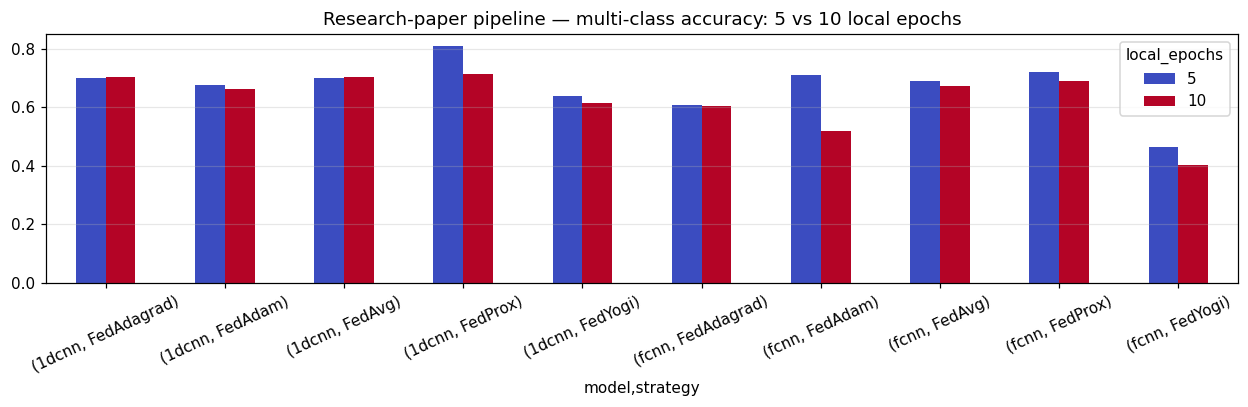

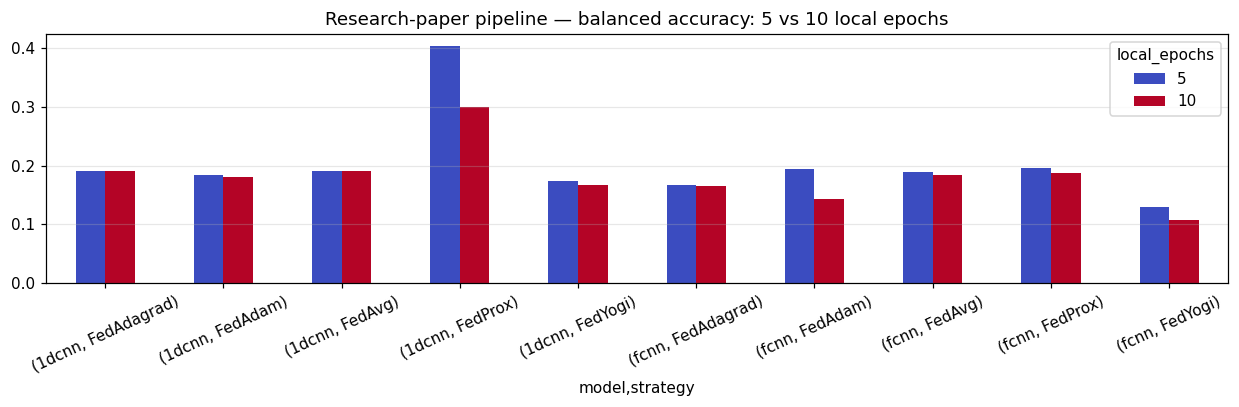

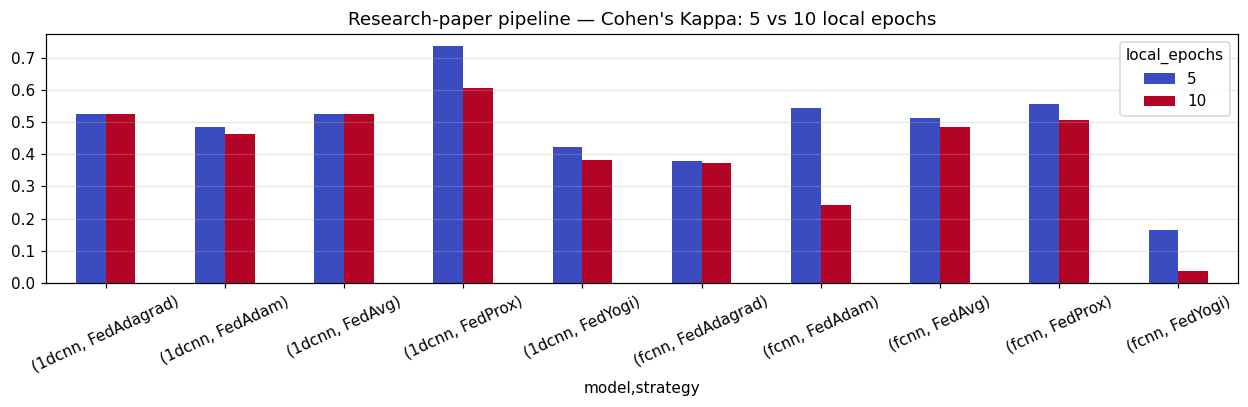

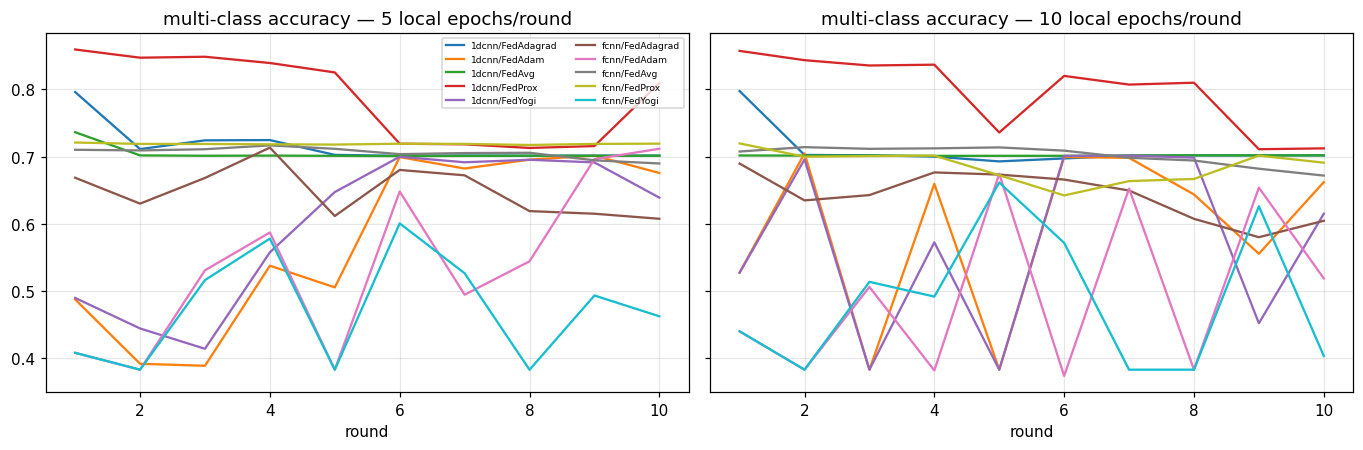

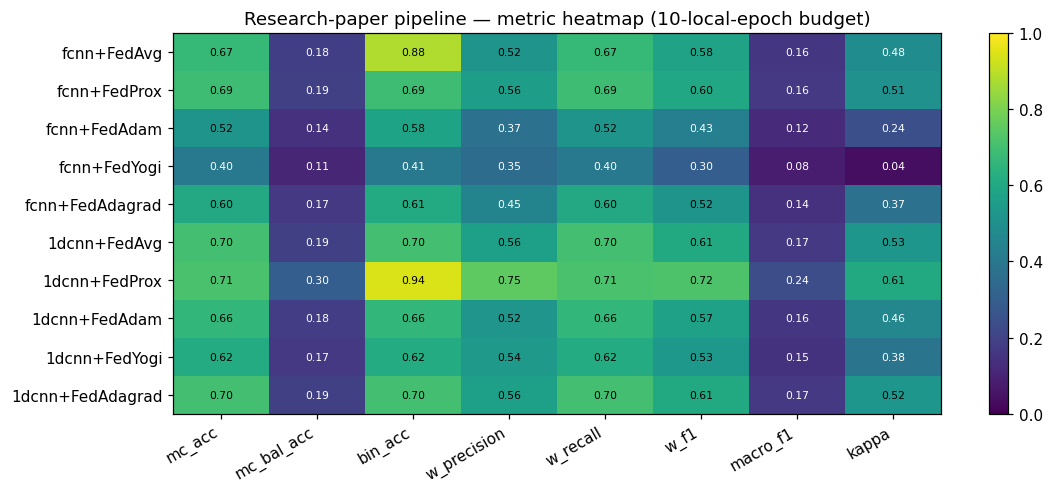

In [29]:
for metric, title in (('mc_acc', 'multi-class accuracy'), ('mc_bal_acc', 'balanced accuracy'),
                      ('kappa', "Cohen's Kappa")):
    piv = paper_epoch.pivot_table(index=['model', 'strategy'], columns='local_epochs', values=metric)
    ax = piv.plot(kind='bar', figsize=(11.5, 3.8), rot=25, colormap='coolwarm')
    ax.set_title(f'Research-paper pipeline — {title}: 5 vs 10 local epochs'); ax.grid(alpha=0.3, axis='y')
    plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2), sharey=True)
for ax, ep in zip(axes, PAPER_EPOCH_BUDGETS):
    for (mk, st), g in paper_epoch_hist[paper_epoch_hist['local_epochs'] == ep].groupby(['model', 'strategy']):
        g = g[g['round'] > 0].sort_values('round')
        ax.plot(g['round'], g['mc_acc'], label=f'{mk}/{st}')
    ax.set_title(f'multi-class accuracy — {ep} local epochs/round'); ax.set_xlabel('round'); ax.grid(alpha=0.3)
axes[0].legend(fontsize=6, ncol=2); fig.tight_layout(); plt.show()

hm = paper_epoch[paper_epoch['local_epochs'] == 10].set_index(['model', 'strategy'])[
    ['mc_acc', 'mc_bal_acc', 'bin_acc', 'w_precision', 'w_recall', 'w_f1', 'macro_f1', 'kappa']]
fig, ax = plt.subplots(figsize=(10.5, 4.6))
im = ax.imshow(hm.values, cmap='viridis', aspect='auto', vmin=0, vmax=1)
ax.set_xticks(range(hm.shape[1]), hm.columns, rotation=30, ha='right')
ax.set_yticks(range(hm.shape[0]), [f'{a}+{b}' for a, b in hm.index])
for i in range(hm.shape[0]):
    for j in range(hm.shape[1]):
        ax.text(j, i, f'{hm.values[i, j]:.2f}', ha='center', va='center', fontsize=7,
                color='white' if hm.values[i, j] < 0.5 else 'black')
ax.set_title('Research-paper pipeline — metric heatmap (10-local-epoch budget)')
fig.colorbar(im); plt.tight_layout(); plt.show()

In [30]:
import os, glob
def _find_json(name):
    """Look for a sibling notebook's export in the working dir first, then in any attached /kaggle/input dataset."""
    if os.path.exists(name): return name
    hits = glob.glob(os.path.join('/kaggle/input', '**', name), recursive=True)
    return hits[0] if hits else name

best_runs = [r for r, h in grid_results if r['model_kind'] == best_model and r['strategy'] == best_strategy]
best_res = best_runs[0]
best_hist = best_res['history'].fillna(0.0)

export = dict(
    pipeline='research-paper (Bierbrauer et al. 2025, EAAI 110685)',
    config=dict(rounds=ROUNDS, local_epochs=LOCAL_EPOCHS, n_samples_per_round=N_SAMPLES_PER_ROUND,
                fedprox_mu=FEDPROX_MU, lr=LR, batch_size=BATCH_SIZE, init_epochs=INIT_EPOCHS, runs=N_RUNS,
                partition_scale=SCALE, n_classes=len(CLASSES)),
    classes=CLASSES,
    final_round_all_combos={f'{m}/{s}': row.to_dict() for (m, s), row in
                            final.groupby(['model', 'strategy'])[METRIC_COLS].mean().round(4).iterrows()},
    best_combo=dict(model=best_model, strategy=best_strategy, per_round=best_hist.to_dict(orient='records')),
    complexity=table1.to_dict(orient='records'),
    async_final=async_final.reset_index().to_dict(orient='records'),
    epoch_budgets=dict(local_epochs=list(PAPER_EPOCH_BUDGETS), sweep_rounds=EPOCH_SWEEP_ROUNDS,
                       sweep=paper_epoch.to_dict(orient='records')))
with open('paper_pipeline_results.json', 'w') as f:
    json.dump(export, f, indent=2, default=float)
print('saved paper_pipeline_results.json')

import os
pb = final[(final['model'] == best_model) & (final['strategy'] == best_strategy)][METRIC_COLS].mean()
paper_col = {f'Paper pipeline ({best_model}+{best_strategy})': {
    'Binary Accuracy': pb['bin_acc'], 'Binary Balanced Accuracy': pb['bin_bal_acc'],
    "Cohen's Kappa (binary)": pb['bin_kappa'], 'Binary F1': pb['bin_f1'],
    'Precision': pb['bin_precision'], 'Recall': pb['bin_recall'],
    'MCC': pb['mcc'], 'AUC': float(pb.get('bin_auc', np.nan)),
    'Parameters': model_facts[best_model]['params'],
    'Model size (MB)': round(model_facts[best_model]['size_MB'], 4),
    'MB per round': round(4 * model_facts[best_model]['params'] * 6 * 2 / 1e6, 4),
    'Avg client-train s/round': round(float(grid_meta[(grid_meta.model == best_model) &
                                                  (grid_meta.strategy == best_strategy)]['avg_client_train_s'].mean()), 3)}}
if os.path.exists(_find_json('advanced_pipeline_results.json')):
    adv = json.load(open(_find_json('advanced_pipeline_results.json')))
    am = adv.get('final_metrics', {})
    acx = adv.get('complexity', {})
    paper_col['Advanced pipeline'] = {
        'Binary Accuracy': am.get('acc'), 'Binary Balanced Accuracy': am.get('balanced_acc'),
        "Cohen's Kappa (binary)": am.get('kappa'), 'Binary F1': am.get('f1'),
        'Precision': am.get('prec'), 'Recall': am.get('rec'),
        'MCC': am.get('mcc'), 'AUC': am.get('auc'),
        'Parameters': acx.get('classifier_params'),
        'Model size (MB)': acx.get('classifier_MB'),
        'MB per round': acx.get('total_MB_per_round'),
        'Avg client-train s/round': acx.get('avg_round_time_s')}
if os.path.exists(_find_json('baseline_pipeline_results.json')):
    blj = json.load(open(_find_json('baseline_pipeline_results.json')))
    bl = blj.get('final_metrics', {})
    bl_disp = {'FcNN': 'FcNN', 'OneD_CNN': '1dCNN'}.get(str(blj.get('best_combo', '')).split('+')[0])
    bl_cx = next((m for m in blj.get('complexity', {}).get('models', []) if m.get('Model') == bl_disp), {})
    paper_col['Baseline pipeline (best)'] = {
        'Binary Accuracy': bl.get('acc'), 'Binary Balanced Accuracy': bl.get('balanced_acc'),
        "Cohen's Kappa (binary)": bl.get('kappa'), 'Binary F1': bl.get('f1'),
        'Precision': bl.get('prec'), 'Recall': bl.get('rec'),
        'MCC': bl.get('mcc'), 'AUC': bl.get('auc'),
        'Parameters': bl_cx.get('Params'),
        'Model size (MB)': bl_cx.get('Size_MB'),
        'MB per round': bl_cx.get('Comm_MB_per_episode'),
        'Avg client-train s/round': bl_cx.get('Avg_time_per_episode_s_5ep')}
comp = pd.DataFrame(paper_col).round(4)
display(comp)
print()
print('paper pipeline multi-class side (best combo, final round):')
print(f"  mc_acc={pb['mc_acc']:.4f} | mc_bal_acc={pb['mc_bal_acc']:.4f} | kappa={pb['kappa']:.4f} "
      f"| w_f1={pb['w_f1']:.4f} | macro_f1={pb['macro_f1']:.4f}")
if 'Advanced pipeline' not in paper_col or 'Baseline pipeline (best)' not in paper_col:
    print('missing sibling JSON(s) -> run the baseline / advanced notebooks, then re-run this cell for the full table.')

pred_best, _ = predict_mc(best_res['model'], df_eval_clean)
cm = confusion_matrix(df_eval_clean['mc_label'].values, pred_best, labels=range(len(CLASSES)))
display(pd.DataFrame(cm, index=[f'true:{c}' for c in CLASSES], columns=[f'pred:{c}' for c in CLASSES]))

saved paper_pipeline_results.json


,Paper pipeline (1dcnn+FedProx)
Binary Accuracy,0.9203
Binary Balanced Accuracy,0.9259
Cohen's Kappa (binary),0.8348
Binary F1,0.9331
Precision,0.9669
Recall,0.9018
MCC,0.6936
AUC,0.9866
Parameters,58850.0000
Model size (MB),0.2354



paper pipeline multi-class side (best combo, final round):
  mc_acc=0.7750 | mc_bal_acc=0.3743 | kappa=0.6845 | w_f1=0.7731 | macro_f1=0.3019
missing sibling JSON(s) -> run the baseline / advanced notebooks, then re-run this cell for the full table.


,pred:Analysis,pred:Backdoor,pred:Benign,pred:DoS/DDoS,pred:Exploits,pred:Fuzzers,pred:Generic,pred:Reconnaissance,pred:Shellcode,pred:Worms
true:Analysis,189,0,3,0,3,1,3,1,0,0
true:Backdoor,138,0,19,0,6,11,0,1,0,0
true:Benign,195,0,14389,39,232,345,165,4,0,0
true:DoS/DDoS,952,0,136,12789,105,18,21,8,0,0
true:Exploits,1463,0,989,1,703,130,31,23,0,0
true:Fuzzers,281,0,606,1,235,499,195,2,0,0
true:Generic,33,0,33,0,14,2,3915,3,0,0
true:Reconnaissance,520,0,106,0,11,401,10,1,0,0
true:Shellcode,37,0,43,0,0,25,8,0,0,0
true:Worms,0,0,8,0,3,2,0,0,0,0
